# Ames Housing: Preis-Klassifikation mit XGBoost

Die Feature-Auswahl aus Aufgabe 1 wird beibehalten. `Order` und `PID` werden nicht als Modellmerkmale verwendet. Fehlende numerische Werte werden mit dem Median, fehlende Kategorien als eigene Kategorie imputiert; kategorische Merkmale werden one-hot-kodiert. Die Preisgrenzen sind linksinklusive: z. B. gehoeren 100.000 zur zweiten und 400.000 zur sechsten Klasse.

In [15]:
from sklearn.base import clone
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

df = pd.read_csv("AmesHousing.csv", sep="\t")

# Dieselben Merkmale wie in der bereinigten Auswahl aus Aufgabe 1.
columns_excluded_in_task1 = [
    "Alley",
    "Mas Vnr Type",
    "Fireplace Qu",
    "Garage Area",
    "Pool QC",
    "Fence",
    "Misc Feature",
    "Yr Sold",
]
df_clean = df.drop(columns=columns_excluded_in_task1).copy()

print(f"Bereinigte Auswahl: {df_clean.shape[0]} Zeilen, {df_clean.shape[1]} Spalten")
display(df_clean.head())

Bereinigte Auswahl: 2930 Zeilen, 74 Spalten


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,IR1,Lvl,AllPub,...,62,0,0,0,0,0,5,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,...,0,0,0,120,0,0,6,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,...,36,0,0,0,0,12500,6,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,Reg,Lvl,AllPub,...,0,0,0,0,0,0,4,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,IR1,Lvl,AllPub,...,34,0,0,0,0,0,3,WD,Normal,189900


In [16]:
class_names = [
    "< 100.000",
    "100.000 - < 130.000",
    "130.000 - < 180.000",
    "180.000 - < 250.000",
    "250.000 - < 400.000",
    ">= 400.000",
]
price_bins = [-np.inf, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]

y = pd.cut(
    df_clean["SalePrice"],
    bins=price_bins,
    labels=False,
    right=False,
).astype("int64")
X = df_clean.drop(columns=["SalePrice", "Order", "PID"])

class_distribution = y.value_counts().sort_index()
display(
    class_distribution.rename(index=dict(enumerate(class_names)))
    .rename("Anzahl")
    .to_frame()
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Trainingsdaten: {X_train.shape[0]} | Testdaten: {X_test.shape[0]}")

,Anzahl
SalePrice,
< 100.000,237
100.000 - < 130.000,509
130.000 - < 180.000,1037
180.000 - < 250.000,686
250.000 - < 400.000,397
>= 400.000,64


Trainingsdaten: 2344 | Testdaten: 586


In [17]:
display(
    pd.DataFrame({
        "SalePrice": df_clean["SalePrice"],
        "class_id": y,
        "price_class": y.map(dict(enumerate(class_names))),
    }).head(10)
)

,SalePrice,class_id,price_class
0,215000,3,180.000 - < 250.000
1,105000,1,100.000 - < 130.000
2,172000,2,130.000 - < 180.000
3,244000,3,180.000 - < 250.000
4,189900,3,180.000 - < 250.000
5,195500,3,180.000 - < 250.000
6,213500,3,180.000 - < 250.000
7,191500,3,180.000 - < 250.000
8,236500,3,180.000 - < 250.000
9,189000,3,180.000 - < 250.000


In [18]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

numeric_preprocessor = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                num_class=len(class_names),
                eval_metric="mlogloss",
                n_estimators=350,
                learning_rate=0.05,
                max_depth=5,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_lambda=1.0,
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [19]:
from scipy import sparse

fitted_preprocessor = model.named_steps["preprocessor"]
encoded_matrix = fitted_preprocessor.transform(X)
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

if sparse.issparse(encoded_matrix):
    X_encoded = pd.DataFrame.sparse.from_spmatrix(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )
else:
    X_encoded = pd.DataFrame(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )

print(f"Kodierter Datensatz: {X_encoded.shape[0]} Zeilen, {X_encoded.shape[1]} Merkmale")
display(X_encoded.head())

Kodierter Datensatz: 2930 Zeilen, 280 Merkmale


,numeric__MS SubClass,numeric__Lot Frontage,numeric__Lot Area,numeric__Overall Qual,numeric__Overall Cond,numeric__Year Built,numeric__Year Remod/Add,numeric__Mas Vnr Area,numeric__BsmtFin SF 1,numeric__BsmtFin SF 2,...,categorical__Sale Type_New,categorical__Sale Type_Oth,categorical__Sale Type_VWD,categorical__Sale Type_WD,categorical__Sale Condition_Abnorml,categorical__Sale Condition_AdjLand,categorical__Sale Condition_Alloca,categorical__Sale Condition_Family,categorical__Sale Condition_Normal,categorical__Sale Condition_Partial
0,20.0,141.0,31770.0,6.0,5.0,1960.0,1960.0,112.0,639.0,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN
1,20.0,80.0,11622.0,5.0,6.0,1961.0,1961.0,NaN,468.0,144.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN
2,20.0,81.0,14267.0,6.0,6.0,1958.0,1958.0,108.0,923.0,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN
3,20.0,93.0,11160.0,7.0,5.0,1968.0,1968.0,NaN,1065.0,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN
4,60.0,74.0,13830.0,5.0,5.0,1997.0,1998.0,NaN,791.0,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,1.0,NaN


In [20]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Mehrheits-Baseline: {baseline_accuracy:.3f}\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)

Accuracy:          0.754
Balanced Accuracy: 0.703
Mehrheits-Baseline: 0.353

                     precision    recall  f1-score   support

          < 100.000       0.73      0.67      0.70        48
100.000 - < 130.000       0.66      0.66      0.66       102
130.000 - < 180.000       0.76      0.84      0.80       207
180.000 - < 250.000       0.82      0.73      0.77       137
250.000 - < 400.000       0.79      0.78      0.79        79
         >= 400.000       0.64      0.54      0.58        13

           accuracy                           0.75       586
          macro avg       0.73      0.70      0.72       586
       weighted avg       0.76      0.75      0.75       586



In [21]:
holdout_results = []
overall_class_shares = y.value_counts(normalize=True).reindex(
    range(len(class_names)), fill_value=0
)

# Das bereits trainierte Modell entspricht dem 20%-Split mit Stratifikation.
holdout_results.append(
    {
        "Verfahren": "Hold-out 20% (stratifiziert)",
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Max. Klassenanteil-Abweichung": (
            y_test.value_counts(normalize=True)
            .reindex(range(len(class_names)), fill_value=0)
            .sub(overall_class_shares)
            .abs()
            .max()
        ),
    }
)

for test_size in (0.1, 0.2):
    for stratified in (True, False):
        if test_size == 0.2 and stratified:
            continue

        X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=42,
            stratify=y if stratified else None,
        )
        experiment_model = clone(model)
        experiment_model.fit(X_train_exp, y_train_exp)
        y_pred_exp = experiment_model.predict(X_test_exp)
        split_name = "stratifiziert" if stratified else "nicht stratifiziert"
        holdout_results.append(
            {
                "Verfahren": f"Hold-out {test_size:.0%} ({split_name})",
                "Train Accuracy": accuracy_score(
                    y_train_exp, experiment_model.predict(X_train_exp)
                ),
                "Test Accuracy": accuracy_score(y_test_exp, y_pred_exp),
                "Test Balanced Accuracy": balanced_accuracy_score(
                    y_test_exp, y_pred_exp
                ),
                "Max. Klassenanteil-Abweichung": (
                    y_test_exp.value_counts(normalize=True)
                    .reindex(range(len(class_names)), fill_value=0)
                    .sub(overall_class_shares)
                    .abs()
                    .max()
                ),
            }
        )

holdout_results = pd.DataFrame(holdout_results)
holdout_results["Train-Test Abstand"] = (
    holdout_results["Train Accuracy"] - holdout_results["Test Accuracy"]
)
display(holdout_results.round(3))

,Verfahren,Train Accuracy,Test Accuracy,Test Balanced Accuracy,Max. Klassenanteil-Abweichung,Train-Test Abstand
0,Hold-out 20% (stratifiziert),0.999,0.754,0.703,0.001,0.244
1,Hold-out 10% (stratifiziert),0.998,0.754,0.688,0.002,0.244
2,Hold-out 10% (nicht stratifiziert),0.998,0.775,0.730,0.064,0.223
3,Hold-out 20% (nicht stratifiziert),0.999,0.778,0.720,0.028,0.221


In [22]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}
cv_summary = []
cv_fold_results = []

for n_splits in (5, 10):
    for stratified in (True, False):
        if stratified:
            cv = StratifiedKFold(
                n_splits=n_splits, shuffle=True, random_state=42
            )
            cv_name = "StratifiedKFold"
        else:
            cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)
            cv_name = "KFold"

        scores = cross_validate(
            clone(model),
            X,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=True,
            n_jobs=1,
            error_score="raise",
        )
        experiment_name = f"{cv_name}, k={n_splits}"
        fold_scores = pd.DataFrame(
            {
                "Verfahren": experiment_name,
                "Fold": np.arange(1, n_splits + 1),
                "Train Accuracy": scores["train_accuracy"],
                "Validation Accuracy": scores["test_accuracy"],
                "Validation Balanced Accuracy": scores[
                    "test_balanced_accuracy"
                ],
            }
        )
        cv_fold_results.append(fold_scores)
        cv_summary.append(
            {
                "Verfahren": experiment_name,
                "Train Accuracy (Mittel)": scores["train_accuracy"].mean(),
                "Validation Accuracy (Mittel)": scores["test_accuracy"].mean(),
                "Validation Accuracy (Std)": scores["test_accuracy"].std(ddof=1),
                "Balanced Accuracy (Mittel)": scores[
                    "test_balanced_accuracy"
                ].mean(),
                "Balanced Accuracy (Std)": scores[
                    "test_balanced_accuracy"
                ].std(ddof=1),
                "Train-Validation Abstand": (
                    scores["train_accuracy"].mean()
                    - scores["test_accuracy"].mean()
                ),
            }
        )

cv_summary = pd.DataFrame(cv_summary)
cv_fold_results = pd.concat(cv_fold_results, ignore_index=True)
display(cv_summary.round(3))
display(cv_fold_results.round(3))

,Verfahren,Train Accuracy (Mittel),Validation Accuracy (Mittel),Validation Accuracy (Std),Balanced Accuracy (Mittel),Balanced Accuracy (Std),Train-Validation Abstand
0,"StratifiedKFold, k=5",0.999,0.753,0.020,0.705,0.011,0.247
1,"KFold, k=5",0.999,0.760,0.026,0.720,0.037,0.239
2,"StratifiedKFold, k=10",0.998,0.760,0.028,0.713,0.041,0.238
3,"KFold, k=10",0.998,0.762,0.027,0.737,0.031,0.236


,Verfahren,Fold,Train Accuracy,Validation Accuracy,Validation Balanced Accuracy
0,"StratifiedKFold, k=5",1,0.999,0.775,0.715
1,"StratifiedKFold, k=5",2,0.999,0.765,0.693
2,"StratifiedKFold, k=5",3,0.999,0.732,0.719
3,"StratifiedKFold, k=5",4,1.000,0.761,0.697
4,"StratifiedKFold, k=5",5,1.000,0.730,0.700
5,"KFold, k=5",1,0.999,0.782,0.718
6,"KFold, k=5",2,0.999,0.732,0.657
7,"KFold, k=5",3,0.999,0.735,0.734
8,"KFold, k=5",4,0.999,0.759,0.736
9,"KFold, k=5",5,0.999,0.790,0.755


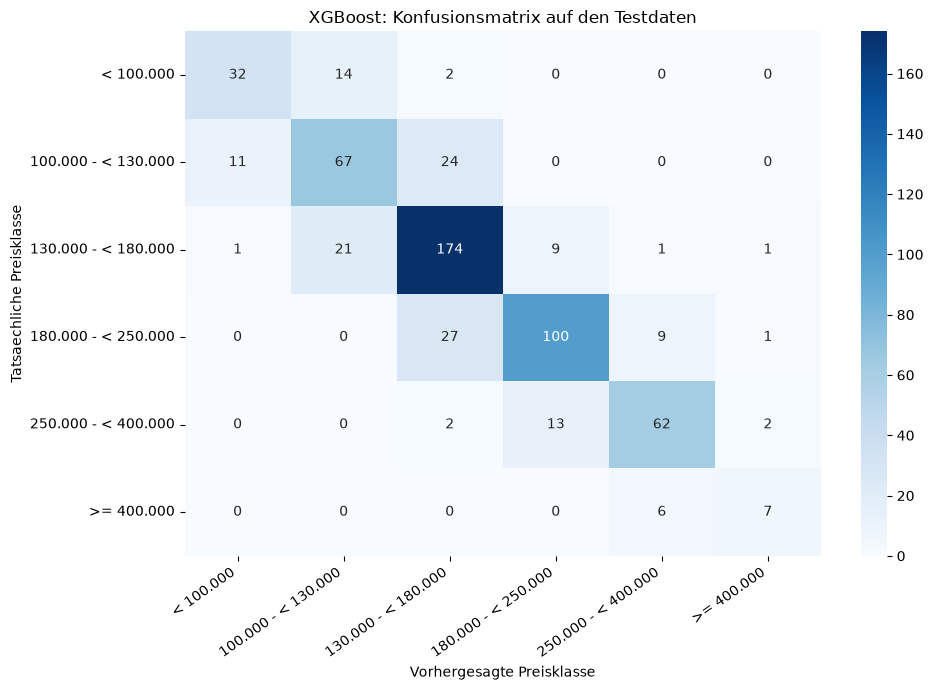

In [23]:
matrix = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Vorhergesagte Preisklasse")
plt.ylabel("Tatsaechliche Preisklasse")
plt.title("XGBoost: Konfusionsmatrix auf den Testdaten")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()